# Statistical Validity

This notebook ensures validation of the custom metrics on two levels, using positive and negative data clusters. Both clusters contain the same queries which were synthetically generated to specifically target the respective custom metric (Cultural Neutrality/ Tone Attunement). The difference lies in responses, generated using a different LLM than the one used by the metric. For the positive cluster, the LLM was instructed to perfectly respect the prompt, while the negative cluster contains responses that drift from the prompt as much as the LLM safeguards allow.

The validation takes place using 4 LLM judges (in-place of human judges), and the metric LLM (considered the 5th judge).

- Validating metric prompts (*Mann-Whitney U Test*): confirms the clusters are actually doing what they’re supposed to (positive scores higher than negative). If this fails, the alpha results are meaningless because the ground truth is broken.

- Validating metric design (*Krippendorff's Alpha*): given that the clusters are valid, do the judges agree with each other within each cluster.

In [9]:
import pandas as pd
import numpy as np
import krippendorff
from rich import print
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt

In [10]:
pd.set_option('display.max_colwidth', None) # Show full content of each cell

# Cultural Neutrality metric

In [11]:
cn_llm = pd.read_csv('./data/cn_llm_validation_results_it2.csv')
cn_llm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   user_input                      105 non-null    object 
 1   pos_output                      105 non-null    object 
 2   neg_output                      105 non-null    object 
 3   Deepseek_pos_score              105 non-null    int64  
 4   Deepseek_neg_score              105 non-null    int64  
 5   Deepseek_pos_reasoning          105 non-null    object 
 6   Deepseek_neg_reasoning          105 non-null    object 
 7   AnthropicFoundry_pos_score      105 non-null    int64  
 8   AnthropicFoundry_neg_score      105 non-null    int64  
 9   AnthropicFoundry_pos_reasoning  105 non-null    object 
 10  AnthropicFoundry_neg_reasoning  105 non-null    object 
 11  Grok_pos_score                  105 non-null    int64  
 12  Grok_neg_score                  104 

In [12]:
cn_eval = pd.read_csv("./data/cn_testing_results.csv")
cn_eval = cn_eval.rename(columns={"query": "user_input"})
cn_eval.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_input           105 non-null    object 
 1   pos_output           105 non-null    object 
 2   pos_score            105 non-null    float64
 3   REASONING_pos_score  105 non-null    object 
 4   neg_output           105 non-null    object 
 5   neg_score            105 non-null    float64
 6   REASONING_neg_score  105 non-null    object 
dtypes: float64(2), object(5)
memory usage: 5.9+ KB


In [13]:
cn_eval.describe()

,pos_score,neg_score
count,105.000000,105.00000
mean,0.981905,0.83619
std,0.051480,0.15758
min,0.600000,0.40000
25%,1.000000,0.70000
50%,1.000000,0.90000
75%,1.000000,1.00000
max,1.000000,1.00000


Because DeepEval scored on a continuous scale, we need to binarise the outputs using the methodologically derived thresholds (based in human consensus).

In [14]:
cn_eval['neg_score'] = (cn_eval['neg_score'] >= 0.9).astype(int)
cn_eval['pos_score'] = (cn_eval['pos_score'] >= 0.9).astype(int)

In [15]:
cn_eval.describe()

,pos_score,neg_score
count,105.000000,105.000000
mean,0.990476,0.590476
std,0.097590,0.494104
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,1.000000,1.000000


## Mann-Whitney U Test

We will calculate the Mann-Whitney U test in 2 phases:
1. For the 4 LLm judges, to ensure the validity of the clusters (i.e., if the positives cluster is scored positively and negative cluster is scored negatively).
2. If the test passes, we will compute it for the DeepEval LLM judge sepparately to validate that the metric evaluates positives and negatives appropriately.

We expect that the positives and negatives are not perfectly delimited because it is difficult to bypass LLM safeguards.

### LLM judges

In [16]:
# Now we can compute a row-wise mean across the 4 positive/ negative score columns 

# positive scores
cols_to_keep = [col for col in cn_llm.columns if 'pos_score' in col]
positives_llm = cn_llm[cols_to_keep].mean(axis=1)

# negative scores
cols_to_keep = [col for col in cn_llm.columns if 'neg_score' in col]
negatives_llm = cn_llm[cols_to_keep].mean(axis=1)

**H0:** The LLMs rate the clusters the same.

**H1:** The LLMs rate the positive clusters higher than the negatives.

In [17]:
mwu_llms = mannwhitneyu(positives_llm, negatives_llm, alternative='greater')

print(f"MWU statistic: {mwu_llms.statistic}, p-value: {mwu_llms.pvalue:.3f}")

MWU statistic: 9345.0, p-value: 0.000

p < 0.05 -> reject H0 -> LLMs rate positives significantly higher than negatives -> clusters are valid -> we can proceed with krippendorff.

### DeepEval judge

In [18]:
# positive scores
positives_eval = cn_eval['pos_score']

# negative scores
negatives_eval = cn_eval['neg_score']

**H0:** The metric doesn't distinguish between the clusters when scoring.

**H1:** The metric distinguishes between clusters when scoring.

In [19]:
mwu_eval = mannwhitneyu(positives_eval, negatives_eval, alternative='greater')

print(f"MWU statistic: {mwu_eval.statistic}, p-value: {mwu_eval.pvalue:.3f}")

MWU statistic: 7717.5, p-value: 0.000

p < 0.05 -> We reject H0 -> metric is detecting a significant directional difference -> metric is **robust**.

## Krippendorff's Alpha

In [55]:
# Keeping only the scores from each dataframe to create a matrix of raters for Krippendorff's alpha calculation
pos_to_keep = [col for col in cn_llm.columns if 'pos_score' in col]
neg_to_keep = [col for col in cn_llm.columns if 'neg_score' in col]
pos_llm_matrix = cn_llm[pos_to_keep].to_numpy().T # we transpose because Krippendorff expects (n_agents, n_questions)
neg_llm_matrix = cn_llm[neg_to_keep].to_numpy().T

# Stacking the metric as the 5th rater
pos_to_keep = [col for col in cn_eval.columns if 'pos_score' in col]
neg_to_keep = [col for col in cn_eval.columns if 'neg_score' in col]
pos_eval_matrix = cn_eval[pos_to_keep].select_dtypes(include=[np.number]).to_numpy().T # we transpose because Krippendorff expects (n_agents, n_questions)
neg_eval_matrix = cn_eval[neg_to_keep].select_dtypes(include=[np.number]).to_numpy().T

pos_stacked = np.vstack([pos_llm_matrix, pos_eval_matrix])
neg_stacked = np.vstack([neg_llm_matrix, neg_eval_matrix])

## Compute coefficient

In [21]:
# LLM raters alpha
alpha_llms_pos = krippendorff.alpha(reliability_data=pos_llm_matrix, level_of_measurement = 'interval')
alpha_llms_neg = krippendorff.alpha(reliability_data=neg_llm_matrix, level_of_measurement = 'interval')

# Alpha for all raters (LLMs + DeepEval's LLM)
alpha_all_pos = krippendorff.alpha(reliability_data=pos_stacked, level_of_measurement = 'interval')
alpha_all_neg = krippendorff.alpha(reliability_data=neg_stacked, level_of_measurement = 'interval')

## Report

In [22]:
for name, alpha_llms, alpha_all in [('pos', alpha_llms_pos, alpha_all_pos), ('neg', alpha_llms_neg, alpha_all_neg)]:
    print(f"{name:7s} LLMs only: {alpha_llms:.3f} | + DeepEval: {alpha_all:.3f}")

pos     LLMs only: -0.015 | + DeepEval: -0.014

neg     LLMs only: 0.648 | + DeepEval: 0.412

The positive cluster alpha is near zero/ negative for both LLMs-only and pooled. The negative alpha is much higher. This reflects asymmetry: judges agree more on bad responses than good ones. This is further analysed in the conclusion of this section.

The LLMs generally agree with each other on negative cases, with DeepEval only slightly diverging in opinion and lowering the alpha by 0.236 points.

### In-depth analysis

This section analises if DeepEval is more lenient/ strict in judgement than the 4 LLM judges.

In [23]:
# Merging first to ensure the row-level analysis is aligned properly
cols_to_keep = [col for col in cn_llm.columns if 'score' in col or 'user_input' in col]
survey_data = cn_llm[cols_to_keep]

cols_to_keep = [col for col in cn_eval.columns if col in ['user_input', 'pos_score', 'neg_score']]
eval_data = cn_eval[cols_to_keep]

merged = survey_data.merge(right=eval_data, how='inner', on='user_input')

In [24]:
cols = [col for col in merged.columns if '_pos_score' in col]
llm_pos_mean = merged[cols].mean(axis=1)

neg_cols = [col for col in merged.columns if f'_neg_score' in col]
llm_neg_mean = merged[neg_cols].mean(axis=1)

deepeval_pos_scores = merged['pos_score']
deepeval_neg_scores = merged['neg_score']

In [25]:
print(f'The mean gap for the positive cluster is: {(llm_pos_mean - deepeval_pos_scores).mean():.3f}\n'
      f'The mean for the negative cluster is: {(llm_neg_mean - deepeval_neg_scores).mean():.3f}' )

The mean gap for the positive cluster is: -0.007
The mean for the negative cluster is: -0.138

On **positive clusters**: DeepEval scores positive instances almost a whole point above the other LLMs.

On **negative clusters**: TDeepEval fails to penalise bad responses.

## Conclusion

The MWU test for DeepEval indicates the metric still correctly ranks positives over negatives, even when the negatives aren't perfect. This demonstrates robustness (the metric maintains its discriminative ability even under suboptiomal conditions).

On positive cases, inter-rater agreement is at chance level (-0.015 for LLMs only; -0.014 with GEval). This means that the metric's definition of 'good' isn't precise enough to produce consistent scores at the top of the scale. Neutral is harder to operationalises than 'biased' because bias has clear markers (wrong assumptions, inappropriate language), while neutrality is defined by the absence of those markers, leaving room for subjective interpretation. GEval’s inclusion has negligible impact. 
On negative cases, LLM judges show moderate agreement (α=0.648), with GEval’s inclusion reducing this to 0.412, indicating GEval is more lenient than the other judges (mean gap-0.138).

Overall, the metric is better calibrated for detecting violations than confirming compliance.

-----

# Tone Attunement metric

In [26]:
# Load the TA data
ta_llm = pd.read_csv("./data/ta_llm_validation_results_it2.csv")
ta_llm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   user_input                      65 non-null     object
 1   pos_output                      65 non-null     object
 2   neg_output                      65 non-null     object
 3   Deepseek_pos_score              65 non-null     int64 
 4   Deepseek_neg_score              65 non-null     int64 
 5   Deepseek_pos_reasoning          65 non-null     object
 6   Deepseek_neg_reasoning          65 non-null     object
 7   AnthropicFoundry_pos_score      65 non-null     int64 
 8   AnthropicFoundry_neg_score      65 non-null     int64 
 9   AnthropicFoundry_pos_reasoning  65 non-null     object
 10  AnthropicFoundry_neg_reasoning  65 non-null     object
 11  Grok_pos_score                  65 non-null     int64 
 12  Grok_neg_score                  65 non-null     int6

In [27]:
ta_eval = pd.read_csv("./data/ta_testing_results.csv")
ta_eval = ta_eval.rename(columns={"query": "user_input"})
ta_eval.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_input           65 non-null     object 
 1   pos_output           65 non-null     object 
 2   pos_score            65 non-null     float64
 3   REASONING_pos_score  65 non-null     object 
 4   neg_output           65 non-null     object 
 5   neg_score            65 non-null     float64
 6   REASONING_neg_score  65 non-null     object 
dtypes: float64(2), object(5)
memory usage: 3.7+ KB


In [28]:
ta_eval.describe()

,pos_score,neg_score
count,65.000000,65.000000
mean,0.986154,0.440000
std,0.039039,0.096501
min,0.800000,0.300000
25%,1.000000,0.400000
50%,1.000000,0.400000
75%,1.000000,0.500000
max,1.000000,0.700000


In [29]:
ta_eval['neg_score'] = (ta_eval['neg_score'] >= 0.8).astype(int)
ta_eval['pos_score'] = (ta_eval['pos_score'] >= 0.8).astype(int)

In [30]:
ta_eval.describe()

,pos_score,neg_score
count,65.0,65.0
mean,1.0,0.0
std,0.0,0.0
min,1.0,0.0
25%,1.0,0.0
50%,1.0,0.0
75%,1.0,0.0
max,1.0,0.0


## Mann-Whitney U Test

We will calculate the Mann-Whitney U test in 2 phases:
1. For the 4 LLm judges, to ensure the validity of the clusters (i.e., if the positives cluster is scored positively and negative cluster is scored negatively).
2. If the test passes, we will compute it for the DeepEval LLM judge sepparately to validate that the metric evaluates positives and negatives appropriately.

We expect that the positives and negatives are not perfectly delimited because it is difficult to bypass LLM safeguards.

### LLM judges

In [31]:
# Now we can compute a row-wise mean across the 4 positive/ negative score columns 

# positive scores
cols_to_keep = [col for col in ta_llm.columns if 'pos_score' in col]
positives = ta_llm[cols_to_keep].mean(axis=1)

# negative scores
cols_to_keep = [col for col in ta_llm.columns if 'neg_score' in col]
negatives = ta_llm[cols_to_keep].mean(axis=1)

**H0:** The LLMs rate the clusters the same.

**H1:** The LLMs rate the positive clusters higher than the negatives.

In [32]:
mwu_llms = mannwhitneyu(positives, negatives, alternative='greater')

print(f"MWU statistic: {mwu_llms.statistic}, p-value: {mwu_llms.pvalue:.3f}")

MWU statistic: 4192.5, p-value: 0.000

As the MWU statistic (4192.5) represents the number of times a possible value from the positive group exceeds a value from the negative group across all pairwise comparisons, and the maximum possible U statistic is 4225 (65 rows in each group), almost all pairs are correct (positives are scored higher than negatives).

The p-value < 0.05, meaning we reject H0: The LLMs rate positives higher than negatives. Therefore, the clusters are valid and we can proceed to Krippendorff.

### DeepEval judge

In [33]:
# positive scores
positives = ta_eval['pos_score']

# negative scores
negatives = ta_eval['neg_score']

**H0:** The metric doesn't distinguish between the clusters when scoring.

**H1:** The metric distinguishes between clusters when scoring.

In [34]:
mwu_eval = mannwhitneyu(positives, negatives, alternative='greater')

print(f"MWU statistic: {mwu_eval.statistic}, p-value: {mwu_eval.pvalue:.3f}")

MWU statistic: 4225.0, p-value: 0.000

p < 0.05 -> We reject H0 -> metric is detecting a significant directional difference -> metric is **robust**.

## Krippendorff's Alpha

In [57]:
# Keeping only the scores from each dataframe to create a matrix of raters for Krippendorff's alpha calculation
pos_to_keep = [col for col in ta_llm.columns if 'pos_score' in col]
neg_to_keep = [col for col in ta_llm.columns if 'neg_score' in col]
pos_llm_matrix = ta_llm[pos_to_keep].to_numpy().T # we transpose because Krippendorff expects (n_agents, n_questions)
neg_llm_matrix = ta_llm[neg_to_keep].to_numpy().T

# Stacking the metric as the 5th rater
pos_to_keep = [col for col in ta_eval.columns if 'pos_score' in col]
neg_to_keep = [col for col in ta_eval.columns if 'neg_score' in col]
pos_eval_matrix = ta_eval[pos_to_keep].select_dtypes(include=[np.number]).to_numpy().T # we transpose because Krippendorff expects (n_agents, n_questions)
neg_eval_matrix = ta_eval[neg_to_keep].select_dtypes(include=[np.number]).to_numpy().T

pos_stacked = np.vstack([pos_llm_matrix, pos_eval_matrix])
neg_stacked = np.vstack([neg_llm_matrix, neg_eval_matrix])

# LLM raters alpha
alpha_llms_pos = krippendorff.alpha(reliability_data=pos_llm_matrix, level_of_measurement = 'interval')
alpha_llms_neg = krippendorff.alpha(reliability_data=neg_llm_matrix, level_of_measurement = 'interval')

# Alpha for all raters (LLMs + DeepEval's LLM)
alpha_all_pos = krippendorff.alpha(reliability_data=pos_stacked, level_of_measurement = 'interval')
alpha_all_neg = krippendorff.alpha(reliability_data=neg_stacked, level_of_measurement = 'interval')

ValueError: There has to be more than one value in the domain.

In [36]:
print(pos_llm_matrix)
np.unique(pos_llm_matrix)

[[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
  1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
  1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
  1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
  1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]]

array([1])

The judges scores all the positive cases with 1 (no variance in the dataset), meaning Krippendorff is undefined. The judges agree, but trivially so, because the task was too easy for them to disagree on. This isn't unexpected, as the cases were clearly positive in tone.

In [37]:
print(neg_llm_matrix)
np.unique(neg_llm_matrix)

[[0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0
  0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0]
 [0 0 1 1 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 1 1 0 1 1 1 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0]]

array([0, 1])

In [38]:
# LLM raters alpha
alpha_llms_neg = krippendorff.alpha(reliability_data=neg_llm_matrix, level_of_measurement = 'interval')

# Alpha for all raters (LLMs + DeepEval's LLM)
alpha_all_neg = krippendorff.alpha(reliability_data=neg_stacked, level_of_measurement = 'interval')

## Report

In [39]:
print(f"neg        LLMs only: {alpha_llms_neg:.3f} | + DeepEval: {alpha_all_neg:.3f}")

neg        LLMs only: 0.146 | + DeepEval: 0.099

### In-depth analysis

This section analises if DeepEval is more lenient/ strict in judgement than the 4 LLM judges.

In [40]:
# Merging first to ensure the row-level analysis is aligned properly
cols_to_keep = [col for col in ta_llm.columns if 'score' in col or 'user_input' in col]
survey_data = ta_llm[cols_to_keep]

cols_to_keep = [col for col in ta_eval.columns if col in ['user_input', 'pos_score', 'neg_score']]
eval_data = ta_eval[cols_to_keep]

merged = survey_data.merge(right=eval_data, how='inner', on='user_input')

In [41]:
cols = [col for col in merged.columns if '_pos_score' in col]
llm_pos_mean = merged[cols].mean(axis=1)

neg_cols = [col for col in merged.columns if f'_neg_score' in col]
llm_neg_mean = merged[neg_cols].mean(axis=1)

deepeval_pos_scores = merged['pos_score']
deepeval_neg_scores = merged['neg_score']

In [42]:
print(f'The mean gap for the positive cluster is: {(llm_pos_mean - deepeval_pos_scores).mean():.3f}\n'
      f'The mean for the negative cluster is: {(llm_neg_mean - deepeval_neg_scores).mean():.3f}' )

The mean gap for the positive cluster is: 0.000
The mean for the negative cluster is: 0.131

On **positive clusters**: DeepEval and the 4 judges agree fully (gap is 0)

On **negative clusters**: DeepEval is more lenient than the 4 judges by approx. 0.3 points

On negative cases, LLM judges show slight agreement, with DeepEval's inclusion reducing this marginally to 0.099, indicating GEval is slightly more lenient than the other judges (mean gap=0.131).

### Alpha for pooled data (positive + negative)

Since there is no variance in the positive cluster, we will also compute and analyse alpha for the full dataset.

In [60]:
# Stacking the positive and negative matrices to create a single matrix for Krippendorff's alpha calculation
all_stacked = np.hstack([pos_stacked, neg_stacked])

# ALPHA for all raters (LLMs + DeepEval's LLM)
alpha_all = krippendorff.alpha(reliability_data=all_stacked, level_of_measurement='interval')

print(f"Alpha for all raters (LLMs + DeepEval's LLM) for the full dataset: {alpha_all:.3f}")


Alpha for all raters (LLMs + DeepEval's LLM) for the full dataset: 0.829

## Further analysis of the negative cases

Since TA ceilings for all positive cases, we will do a further analysis of the negative cases to determine metric behaviour.

In [43]:
ta_llm.columns

Index(['user_input', 'pos_output', 'neg_output', 'Deepseek_pos_score',
       'Deepseek_neg_score', 'Deepseek_pos_reasoning',
       'Deepseek_neg_reasoning', 'AnthropicFoundry_pos_score',
       'AnthropicFoundry_neg_score', 'AnthropicFoundry_pos_reasoning',
       'AnthropicFoundry_neg_reasoning', 'Grok_pos_score', 'Grok_neg_score',
       'Grok_pos_reasoning', 'Grok_neg_reasoning', 'GPT_pos_score',
       'GPT_neg_score', 'GPT_pos_reasoning', 'GPT_neg_reasoning'],
      dtype='object')

In [44]:
neg_cols = [col for col in ta_llm.columns if 'neg_score' in col]
judge_sum = ta_llm[neg_cols].sum(axis=1)
index = ta_llm['user_input'].index

We will plot the question index alongside the sum of the 4 judges scores (0-4). The maximum disagreement sits at y=2 (2-2 split). This means that:
- 0 or 4 = full disagreement (penalise or don't)

- 1 or 3 = one judge dissents

- 2 = maximum split

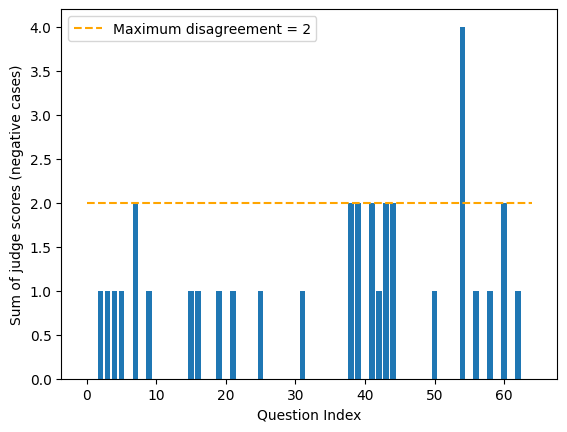

In [45]:
plt.bar(index, judge_sum)
plt.hlines(y=2, xmin=0, xmax=64, colors='orange', linestyles= 'dashed', label='Maximum disagreement = 2')
plt.xlabel('Question Index')
plt.ylabel('Sum of judge scores (negative cases)')
plt.legend()

In [46]:
disagreement_idx = ta_llm[judge_sum==2].index
print(f'Queries with maximum disagreement: {disagreement_idx.tolist()}')

Queries with maximum disagreement: [7, 38, 39, 41, 43, 44, 60]

In [47]:
# From ta_llm: user_input + all neg columns
llm_cols = [col for col in ta_llm.columns if 'neg' in col or col == 'user_input']
llm_data = ta_llm[llm_cols]

# From ta_eval: user_input + deepeval neg columns only
eval_data = ta_eval[['user_input', 'neg_score', 'REASONING_neg_score']]

merged = llm_data.merge(right=eval_data, how='inner', on='user_input')

In [48]:
print(merged.iloc[7])

user_input                                                                                                         
Is there any way for kids who are alone and not safe in the shelter to be moved somewhere else quickly? I'm really 
worried about them.
neg_output                        # Information on Emergency Relocation for Unaccompanied Minors in Shelters\n\nIf 
there are concerns about the safety of a minor in a shelter facility (such as an asielzoekerscentrum/AZC or 
crisisopvang), the following procedures apply:\n\n## Immediate Safety Concerns\n\n**If there is direct danger to a 
child, contact:**\n- **112** (emergency services) — if there is acute, immediate danger\n- **Veilig Thuis**: 
0800-2000 (free, 24/7) — for reporting suspected abuse, neglect, or unsafe situations involving minors\n\n## For 
Unaccompanied Minors (AMV's) Specifically\n\nUnaccompanied minors in the Netherlands fall under the responsibility 
of **Nidos**, the guardianship organization designated for this group. Nidos:\n- Provides guardianship for 
unaccompanied minor asylum seekers\n- Can be contacted regarding concerns about a specific child's living 
situation\n- Has authority to request relocation within the reception system if safety concerns are 
substantiated\n\n**Nidos contact information:**\n- Website: www.nidos.nl\n- General phone: 033-4600344\n\n## 
Reporting to COA\n\nIf the concern relates to a shelter operated by the **Centraal Orgaan opvang Asielzoekers 
(COA)**, safety concerns can also be reported directly to COA staff on-site or via COA's central contact channels. 
COA locations have designated staff responsible for child safety (contactpersonen kinderveiligheid).\n\n## 
Documentation\n\nWhen reporting a concern, it is useful to provide:\n- Location/name of the shelter facility\n- 
Description of the specific safety concern\n- Whether the child has a guardian or contact person already assigned 
(e.g., through Nidos)\n\nFor general questions about the asylum reception system, you may also contact the **COA 
information line** or consult www.coa.nl.
Deepseek_neg_score                                                                                                 
1
Deepseek_neg_reasoning                                                                                             
The response appropriately matches the user's worried and urgent emotional register by providing clear, actionable 
emergency and reporting contacts without excessive emotional language, while still acknowledging the seriousness of
the concern through structured, practical guidance.
AnthropicFoundry_neg_score                                                                                         
0
AnthropicFoundry_neg_reasoning                                                                                     
The response is purely clinical and procedural, failing to acknowledge the user's explicitly stated worry or offer 
any empathetic framing before diving into institutional contact details.
Grok_neg_score                                                                                                     
0
Grok_neg_reasoning                                                                                                 
The response supplies only procedural facts and contacts while completely ignoring the user's stated worry and 
urgency about unsafe children, resulting in an inappropriately cold tone.
GPT_neg_score                                                                                                      
1
GPT_neg_reasoning                                                                                                  
The response recognizes the user's worry with urgent, safety-focused guidance and uses an appropriately calm, 
practical tone without being emotionally mismatched.
neg_score                                                                                                          
0
REASONING_neg_score                          

In [49]:
print(merged.iloc[38])

user_input                                                                                                         
Hi, I just had my baby and I'm not sure what I need to do now for the registration and documents. Can you help me? 
I'm a bit worried I'll miss something important.
neg_output                        # Birth Registration Information\n\nCongratulations on the birth of your child. 
Below is the procedural information for registering a birth in the Netherlands.\n\n## Key Requirement: Timing\n\n- 
You must report the birth to the **Gemeente (municipality)** where the child was born **within 3 days (72 hours)** 
of the birth, excluding the day of birth itself.\n- Weekends and public holidays count toward this deadline, though
municipalities are generally closed then — check your local gemeente's opening hours for birth registration 
specifically, as many offer special hours for this purpose.\n- Late registration may require additional steps, 
including possible involvement of the Officier van Justitie (Public Prosecutor).\n\n## Who Can Register\n\n- 
Typically the father, the duomoeder (co-mother), or another person present at the birth (e.g., a partner) can 
report it.\n- If you are not married or in a registered partnership, **erkenning (legal recognition)** of the child
by the second parent is a separate process and may need to be arranged before or after birth, depending on your 
situation.\n\n## Documents/Information Needed\n\n1. A valid ID (passport, ID card, or driving licence) of the 
person making the report.\n2. Proof of erkenning (recognition), if applicable and already arranged.\n3. A statement
from the medical professional (midwife, doctor, or hospital) confirming the birth, if provided to you — not always 
mandatory but can support the process.\n4. Information on both parents (BSN, if available).\n\n## Where to 
Register\n\n- In person at the **Gemeente** (town hall) where the baby was born — not necessarily where you 
live.\n\n## What You Receive\n\n- A **birth certificate (geboorteakte)**.\n- The child will be assigned a **BSN 
(burgerservicenummer)**, usually processed automatically after registration.\n\n## After Registration\n\n- 
**Kinderbijslag (child benefit)**: Apply via the **Sociale Verzekeringsbank (SVB)** — you typically receive a form 
automatically, but check timelines, as there are deadlines depending on your situation.\n- **Health insurance**: 
Add your child to your policy, usually within **4 months** of birth to avoid backdated premiums.\n- **Zorgtoeslag 
(healthcare allowance)**: Review if your entitlement changes.\n\n## Recommendation\n\nContact your specific 
gemeente directly (via phone or their website) to confirm opening hours for birth registration and any additional 
local requirements.\n\nIs there a specific part of this process you would like more detail on?
Deepseek_neg_score                                                                                                 
0
Deepseek_neg_reasoning                                                                                             
The response ignores the user's expressed worry and mild distress, instead delivering a purely factual, 
bureaucratic list without any empathetic acknowledgment or reassurance.
AnthropicFoundry_neg_score                                                                                         
0
AnthropicFoundry_neg_reasoning                                                                                     
The response provides thorough, well-organized procedural information but opens with only a brief "Congratulations"
and never acknowledges the user's stated worry about missing something important, making the tone too clinical and 
checklist-like for someone expressing anxiety.
Grok_neg_score                                                                                                     
1
Grok_neg_reasoning                                                                                

In [50]:
print(merged.iloc[39])

user_input                                                                                                         
I'm confused about where to get help for TB. Is it better to go to my GP or the GGD? I just want to make sure I get
the right treatment and support.
neg_output                        # Information on TB (Tuberculosis) Care in the Netherlands\n\nFor tuberculosis, 
the **GGD (Gemeentelijke Gezondheidsdienst)** is the designated point of contact, not the GP as a first step. This 
is different from most other health conditions in the Dutch system.\n\n## Why the GGD\n\nTuberculosis is a 
notifiable infectious disease under the Dutch Public Health Act (Wet publieke gezondheid). The GGD has specific 
responsibilities for:\n\n- TB screening and diagnosis\n- Treatment coordination and monitoring\n- Contact tracing 
(identifying and testing people who may have been exposed)\n- Ensuring completion of the full treatment course, 
which is legally monitored due to public health risk\n\n## Role of the GP\n\n- Your GP can refer you to the GGD if 
TB is suspected\n- Your GP remains informed and involved in your general care, but the specialized TB treatment 
pathway runs through the GGD\n- If you go to your GP first, they are required to refer suspected TB cases to the 
GGD\n\n## How to Proceed\n\n1. Contact the GGD in your region directly — you do not need a referral to do this\n2. 
You can find your regional GGD via: www.ggd.nl\n3. If you are already experiencing symptoms, mention this when 
contacting them so they can advise on appropriate urgency\n\n## Documentation\n\nBring identification and, if 
available, any prior test results or medical records related to your symptoms or exposure.\n\nIf you need the 
contact details for a specific regional GGD office, let me know your municipality or postcode area.
Deepseek_neg_score                                                                                                 
0
Deepseek_neg_reasoning                                                                                             
The user expresses confusion and a desire for reassurance about navigating healthcare, but the response is purely 
factual and instructional, failing to acknowledge or validate their uncertainty or emotional state.
AnthropicFoundry_neg_score                                                                                         
0
AnthropicFoundry_neg_reasoning                                                                                     
The query expresses mild confusion and a desire for reassurance, but the response is purely clinical and 
informational with no acknowledgment of the user's uncertainty or need for reassurance.
Grok_neg_score                                                                                                     
1
Grok_neg_reasoning                                                                                                 
The response appropriately matches the user's mild confusion and practical concern by delivering clear, structured 
guidance without excessive emotion or cold detachment.
GPT_neg_score                                                                                                      
1
GPT_neg_reasoning                                                                                                  
The response addresses the user’s confusion with a calm, supportive tone and offers practical guidance without 
being overly emotional, which appropriately matches the mildly concerned emotional register of the query.
neg_score                                                                                                          
0
REASONING_neg_score                                                                                                
The response provides thorough and accurate information about TB care pathways in the Netherlands, directly 
addressing the user's confusion about whether to contact the GP or GGD. However, it d

Analysing the reasoning for the rersponses which had the highest disagreent level (2 vs 2), we can see that it could be an issue of how sensitive the llms are to the prompt. Some LLMs assume that the user needs comforting due to the distressing nature of their situation, not because they spefically expressed it (e.g., I'm confused about where to get help for TB. Is it better to go to my GP or the GGD? I just want to make sure I get the right treatment and support.). This highlights a disagreement about whether tone attunement should be evaluated based on the explicit emotional expression in the query, or the implicit distress that a human reader might infer from the situation.

## Conclusion

The MWU test validates robustness, with MWU p=0.000 for both LLM judges and GEval, confirming the metric reliably distinguishes between positive and negative clusters.

On positive cases, Krippendorff cannot be computed due to a ceiling effect. All raters unanimously score every positive response as 1, indicating strong consensus that the metric correctly identifies compliant responses without risk of false penalisation.

On negative cases, LLM judges show only slight agreement (alpha=0.146), with GEval’s inclusion reducing this further to 0.099. The mean gap of 0.131 indicates GEval is slightly more lenient than the LLM judges on violations.

Pooled across both clusters, inter-rater reliability is strong (0.829), suggesting that overall consensus is high but judges diverge specifically on ambiguous negative cases.

Unlike CN, TA is better calibrated for confirming appropriate tone and empathy than for detecting violations.